# Effectiveness of thrombolysis and thrombectomy in early (6hr) arrivals of non-mild stroke - Causal Forest

**Good outcome = discharged mRS or at same mRS as pre-stroke mRS**


To estimate how the effect of thrombolysis and thrombectomy varied between patients, we used a causal forest estimated within a double machine learning framework (CausalForestDML, EconML). In clinical terms, the method asks: for patients who look alike, did those who received thrombolysis do better than we would have expected them to? It works in two stages.

In the first stage, two prediction models were built with gradient-boosted decision trees (LightGBM). The first predicted each patient's probability of a good outcome from their baseline characteristics and stroke team, without knowing the treatment given. These characteristics were age, stroke severity, pre-stroke disability, comorbidities, atrial fibrillation and anticoagulation status, and ethnicity. The second predicted the probability of each of the eight treatment groups (neither, or thrombolysis and/or thrombectomy, each early or late) from the same information. It therefore captures the clinical and organisational factors that influence who is treated.

The models used five-fold cross-fitting, so each patient's predictions came from models trained on other patients. Subtracting the predictions from what actually happened left two residuals: how much better or worse each patient's outcome was than expected, and how far their treatment differed from what would typically be given to someone like them. Removing the predictable part of both treatment and outcome adjusts for measured confounding, including confounding by indication. A further advantage is that small errors in either prediction model have only a limited, second-order effect on the final estimates.

In the second stage, a forest of 2,000 "honest" trees related the outcome residuals to the treatment residuals. Each tree used one half of its data to choose how to split patients into subgroups and the other half to estimate the treatment effect within them, which reduces overfitting. The result was an estimated absolute change in the probability of a good outcome for each patient under each treatment strategy compared with neither treatment. These estimates were then summarised by treatment window and by patient characteristics.

As with any observational analysis, the estimates assume there is no important unmeasured confounding, and that comparable patients were found in both the treated and untreated groups.

![](./images/dml_causal_forest_thrombolysis_method.png)

## Overview

### What this notebook estimates

Each patient is in one of eight treatment groups ("neither", or thrombolysis and/or thrombectomy, each early or late; early = thrombolysis within 270 min or thrombectomy before 270 min). The causal forest estimates, for each treatment strategy compared with neither:

| Estimate | Meaning | How it is calculated |
|---|---|---|
| **ATT** (main result) | Average effect in patients who actually received that strategy | Doubly robust (augmented inverse-probability-weighted, AIPW) estimate from the cross-fitted first-stage models and the forest, with 95% CI |
| **ATE** | Average effect if *everyone* in the cohort received that strategy | AIPW estimate over all patients, with 95% CI. Only reported where positivity holds for most of the cohort |
| **Mean CATE in treated** | Simple average of the forest's individual-level (conditional) effect estimates in patients who received that strategy | Plug-in average (no CI) |

The ATT is the most relevant estimate. It answers the same question as the matched target trial emulation (effect in the treated), so the two can be compared directly. The ATE extrapolates each treatment to patients who would rarely receive it (for example thrombectomy for patients unlikely to have a large vessel occlusion), so it relies more on the model.

### Changes from the earlier version of this notebook

* **Categorical features are now passed to LightGBM correctly.** EconML gives the first-stage models the combined matrix `[X, W]`, but the categorical column indices were calculated for `X` and `W` separately. As a result, stroke team was treated as a numeric code and a copy of pre-stroke mRS was treated as categorical. The indices now refer to the combined matrix. The effect of this fix is shown as a sensitivity analysis.
* **Confidence intervals are now valid.** The earlier table used mean ± 1.96 × SD / √n of the individual CATE estimates. That SD measures how much the estimates *vary between patients*, not how uncertain the average is, so those intervals were far too narrow. The CIs now come from doubly robust (AIPW) influence functions.
* **AIPW is calculated directly, with clipped propensities.** EconML's built-in doubly robust ATT/ATE (`att__inference`, `ate__inference`) divide by unclipped treatment probabilities. For the rare treatment groups the treatment model predicts probabilities very close to zero for some patients, so those estimates blow up (for example, an ATT of −8,082 percentage points for late both). Here propensities are clipped at 0.01, and the ATT uses the form that reweights only untreated patients. The built-in values are shown for comparison.
* **Onset-to-scan time is now calculated correctly.** It was calculated as onset-to-arrival *minus* arrival-to-scan time instead of *plus*, which gave negative times for 6.2% of patients. Onset-to-scan time is a confounder in the primary model, so this changed the early-strategy estimates (see the sensitivity analyses).
* **New checks:** first-stage model performance, overlap (positivity), effect heterogeneity, comparison with the matched target trial emulation, sensitivity analyses and E-values.
* **Code tidied:** functions are shared by the primary and sensitivity analyses, and unused imports and code are removed.

### Notebook structure

1. Settings and features
2. Cohort selection and treatment groups
3. Descriptive statistics
4. Model definition and fitting
5. Model diagnostics: first-stage performance and overlap
6. Treatment effects (ATT, ATE, mean CATE)
7. Heterogeneity of effects
8. Comparison with the matched target trial emulation
9. Sensitivity analyses
10. Conclusions and limitations

### Key findings

* **Every strategy is associated with a higher probability of a good outcome in the patients who received it.** ATTs range from +9.3 percentage points (early thrombolysis then late thrombectomy) to +15.4 (late both; only 141 patients). All 95% CIs exclude zero.
* **Earlier thrombectomy is better:**
  * Thrombectomy only: +12.1 points early vs +9.4 late.
  * After early thrombolysis: +15.2 with early thrombectomy vs +9.3 with late thrombectomy.
* **Thrombolysis alone:** the early–late difference is small (+9.9 vs +9.5).
* **Agreement with the matched target trial emulation is mixed:**
  * The late strategies agree to within 3 points.
  * The causal forest gives smaller effects for the early strategies: early both +15.2 vs +23.5, early thrombectomy only +12.1 vs +17.2, early thrombolysis only +9.9 vs +12.4.
  * The difference is almost entirely due to adjustment for onset-to-scan time. Without it, the causal forest gives +24.0, +18.6 and +13.2, very close to the target trial emulation.
* **Robust to model settings:** random seeds, trimming of poor-overlap patients, first-stage and forest settings, and the categorical-feature fix change most estimates by about 2 points or less.
* **More sensitive to analysis choices:** which confounders are adjusted for (onset-to-scan time, LVO), cross-fitting by stroke team, and the outcome definition.
* **ATE:** the effect over the whole cohort can only be estimated for early thrombolysis only (+8.8 points). For every other strategy, most patients have almost no chance of receiving it.

## Load modules

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from econml.dml import CausalForestDML  # causal forest within double machine learning
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score

warnings.filterwarnings('ignore')

## Settings

All analysis choices are set here. The sensitivity analyses change one at a time.

In [2]:
prefix = "non_mild_stroke_early_arrival_good_outcome_causal_forest"
DATA_PATH = "../data/sam3/cleaned_data.csv"
OUTPUT_DIR = "./output"
TTE_SUMMARY_PATH = ("../4_target_trial_emulation/output/"
                    "non_mild_stroke_early_arrival_good_outcome_target_trial_summary.csv")

MRS_TARGET = 2          # good outcome: discharge mRS <= MRS_TARGET, or no worse than pre-stroke mRS
CUTOFF = 270            # minutes from onset separating early from late treatment
NO_TREATMENT = 99999    # sentinel time meaning "treatment not given"
SEED = 42

# First-stage (nuisance) models: LightGBM gradient-boosted trees
NUISANCE_PARAMS = dict(n_estimators=400, num_leaves=31, learning_rate=0.03,
                       subsample=0.8, colsample_bytree=0.8, n_jobs=-1, verbosity=-1)
CV_FOLDS = 5            # cross-fitting folds
PROPENSITY_CLIP = 0.01  # lower limit for treatment probabilities in the AIPW estimates
ATE_MAX_CLIPPED_PCT = 20  # report ATE only if fewer than this % of patients have P(strategy) < PROPENSITY_CLIP

# Second stage: causal forest
N_TREES = 2000
MIN_SAMPLES_LEAF = 25

TIME_THROMBOLYSIS = "onset_to_thrombolysis_time"
TIME_THROMBECTOMY = "onset_to_thrombectomy_time"

## Define features

* **X (effect modifiers):** pre-treatment clinical features that the effect of treatment may vary with. The forest splits on these to find subgroups with different effects.
* **W (confounders):** features adjusted for in the first-stage models but not used for splitting. Many variables are both a confounder and an effect modifier, so they appear in both. W also includes:
  * stroke team, which captures differences in practice between hospitals
  * year
  * onset-to-scan time, which strongly predicts whether treatment can be given early
* **Categorical features** (stroke team, ethnicity) are coded as integers and handled natively by LightGBM.

In [3]:
X_FEATURES = [
    'prior_disability',
    'stroke_severity',
    'age',
    'congestive_heart_failure',
    'hypertension',
    'diabetes',
    'afib_anticoagulant',
    'any_afib_diagnosis',
    'ethnicity',
]

W_FEATURES = X_FEATURES + [
    'stroke_team',
    'year',
    'onset_to_scan_time',
]

CATEGORICAL_FEATURES = ['stroke_team', 'ethnicity']
TREATMENT_TIMES = [TIME_THROMBOLYSIS, TIME_THROMBECTOMY]

# Treatment groups. EconML one-hot encodes a discrete treatment and uses the first level
# (alphabetically) as the baseline, so codes are prefixed with a number to fix the order.
CONTROL_GROUP = "neither"
GROUP_ORDER = [
    'early_thrombolysis_only',
    'late_thrombolysis_only',
    'early_thrombectomy_only',
    'late_thrombectomy_only',
    'early_both',
    'early_thrombolysis_late_thrombectomy',
    'late_both',
]
ARM_CODES = {g: f"{i}_{g}" for i, g in enumerate([CONTROL_GROUP] + GROUP_ORDER)}
BASELINE_ARM = ARM_CODES[CONTROL_GROUP]
GROUP_LABELS = {
    'early_thrombolysis_only': 'Early thrombolysis only',
    'late_thrombolysis_only': 'Late thrombolysis only',
    'early_thrombectomy_only': 'Early thrombectomy only',
    'late_thrombectomy_only': 'Late thrombectomy only',
    'early_both': 'Early both',
    'early_thrombolysis_late_thrombectomy': 'Early thrombolysis,\nlate thrombectomy',
    'late_both': 'Late both',
}

## Cohort selection and treatment groups

The cohort is the same as in the matched target trial emulation (`4_target_trial_emulation/01_...`). Patients are included if they:

* had an ischaemic stroke, arrived within 6 hours of onset, and had a recorded discharge mRS
* had no perfusion imaging
* had NIHSS > 5 or a large vessel occlusion
* were seen by a team that gave at least 10 thrombectomies

Records with implausible treatment times are removed. Unlike matching, the causal forest needs complete data for every feature, so patients with any missing feature are excluded. This removes 67 patients (74,611 vs 74,678).

Treatment groups use the same rules as the target trial emulation. A patient with late thrombolysis and thrombectomy at exactly 270 minutes matches no rule and stays in "neither", as in that notebook.

In [4]:
def assign_treatment_groups(df, cutoff=CUTOFF):
    # Label each patient with a treatment strategy; later rules overwrite earlier ones
    lysis, ect = df[TIME_THROMBOLYSIS], df[TIME_THROMBECTOMY]
    has_lysis, has_ect = lysis != NO_TREATMENT, ect != NO_TREATMENT
    group = pd.Series(CONTROL_GROUP, index=df.index)
    group[(lysis <= cutoff) & ~has_ect] = "early_thrombolysis_only"
    group[(lysis > cutoff) & has_lysis & ~has_ect] = "late_thrombolysis_only"
    group[~has_lysis & (ect < cutoff)] = "early_thrombectomy_only"
    group[~has_lysis & (ect >= cutoff) & has_ect] = "late_thrombectomy_only"
    group[(lysis <= cutoff) & (ect < cutoff)] = "early_both"
    group[(lysis <= cutoff) & (ect >= cutoff) & has_ect] = "early_thrombolysis_late_thrombectomy"
    group[(lysis > cutoff) & has_lysis & (ect > cutoff) & has_ect] = "late_both"
    df["treatment_group"] = group
    return df


def build_cohort(raw, cutoff=CUTOFF, extra_features=(), verbose=False):
    # Apply eligibility criteria, keep model features, drop incomplete rows, add treatment groups.
    # extra_features: additional columns to keep (missing values coded as -1, not dropped).
    df = raw.copy()
    df["onset_to_scan_time"] = df["onset_to_arrival_time"] + df["arrival_to_scan_time"]
    log = [("All records", len(df))]

    def keep_rows(label, mask):
        nonlocal df
        df = df[mask]
        log.append((label, len(df)))

    keep_rows("Discharge mRS recorded", df["discharge_disability"].notna())
    keep_rows("Infarction", df["infarction"] == 1)
    keep_rows("Arrival within 360 min of onset", df["onset_to_arrival_time"] < 360)
    keep_rows("No perfusion imaging", df["perfusion_imaging_used"] == 0)
    keep_rows("NIHSS > 5 or LVO", (df["stroke_severity"] > 5) | (df["lvo"] == 1))
    team_counts = df.groupby("stroke_team")[TIME_THROMBECTOMY].count()
    keep_rows("Team gave >= 10 thrombectomies", df["stroke_team"].isin(team_counts.index[team_counts >= 10]))

    df = df.copy()
    df[TREATMENT_TIMES] = df[TREATMENT_TIMES].fillna(NO_TREATMENT)
    lysis, ect = df[TIME_THROMBOLYSIS], df[TIME_THROMBECTOMY]
    keep_rows("Thrombolysis not after thrombectomy", ~((lysis < NO_TREATMENT) & (ect < NO_TREATMENT) & (lysis > ect)))
    keep_rows("Thrombectomy (if given) < 720 min", (df[TIME_THROMBECTOMY] < 720) | (df[TIME_THROMBECTOMY] == NO_TREATMENT))
    keep_rows("Thrombolysis (if given) < 360 min", (df[TIME_THROMBOLYSIS] < 360) | (df[TIME_THROMBOLYSIS] == NO_TREATMENT))

    columns = list(dict.fromkeys(X_FEATURES + W_FEATURES + TREATMENT_TIMES + ["discharge_disability"]))
    df = df[columns + list(extra_features)].copy()
    for feature in extra_features:
        df[feature] = df[feature].fillna(-1)
    keep_rows("Complete data for all model features", df.notna().all(axis=1))

    df = assign_treatment_groups(df.copy(), cutoff)
    df["patient_id"] = np.arange(len(df))
    if verbose:
        display(pd.DataFrame(log, columns=["Step", "Patients remaining"]))
    return df


raw_data = pd.read_csv(DATA_PATH, low_memory=False)
data = build_cohort(raw_data, verbose=True)
data["treatment_group"].value_counts().reindex([CONTROL_GROUP] + GROUP_ORDER).rename("patients").to_frame()

,Step,Patients remaining
0,All records,452863
1,Discharge mRS recorded,438589
2,Infarction,384365
3,Arrival within 360 min of onset,163932
4,No perfusion imaging,161607
5,NIHSS > 5 or LVO,77938
6,Team gave >= 10 thrombectomies,75535
7,Thrombolysis not after thrombectomy,75514
8,Thrombectomy (if given) < 720 min,75124
9,Thrombolysis (if given) < 360 min,74678


,patients
treatment_group,
neither,37602
early_thrombolysis_only,27675
late_thrombolysis_only,1189
early_thrombectomy_only,1107
late_thrombectomy_only,1876
early_both,2307
early_thrombolysis_late_thrombectomy,2714
late_both,141


**What this shows:** 74,611 patients are included. 37,602 received neither treatment. Early thrombolysis only is by far the largest treated group (27,675), and late thrombolysis plus late thrombectomy is the smallest (141).

## Descriptive statistics

Baseline characteristics by treatment type (ignoring timing), shown as mean ± SD. The differences between groups are the confounding that the first-stage models have to remove.

In [5]:
has_lysis = data[TIME_THROMBOLYSIS] != NO_TREATMENT
has_ect = data[TIME_THROMBECTOMY] != NO_TREATMENT
treatment_type = np.select([has_lysis & has_ect, has_lysis, has_ect],
                           ["both", "thrombolysis_only", "thrombectomy_only"], default="neither")

descriptive_features = [f for f in W_FEATURES if f not in CATEGORICAL_FEATURES + ["year", "onset_to_scan_time"]]
stats_by_type = data[descriptive_features].groupby(treatment_type).agg(["mean", "std", "count"])

type_order = ["neither", "thrombolysis_only", "thrombectomy_only", "both"]
formatted_descriptive_stats = pd.DataFrame({
    t.replace("_", " "): [f"{stats_by_type.loc[t, (f, 'mean')]:.2f} ± {stats_by_type.loc[t, (f, 'std')]:.2f} "
                          f"(n={int(stats_by_type.loc[t, (f, 'count')])})" for f in descriptive_features]
    for t in type_order
}, index=[f.replace("_", " ") for f in descriptive_features])
formatted_descriptive_stats

,neither,thrombolysis only,thrombectomy only,both
prior disability,1.87 ± 1.60 (n=37602),1.00 ± 1.31 (n=28864),0.67 ± 0.87 (n=2983),0.42 ± 0.73 (n=5162)
stroke severity,12.81 ± 6.75 (n=37602),12.59 ± 6.15 (n=28864),16.74 ± 6.17 (n=2983),16.67 ± 6.05 (n=5162)
age,78.51 ± 12.38 (n=37602),74.19 ± 13.32 (n=28864),72.38 ± 13.30 (n=2983),69.96 ± 13.34 (n=5162)
congestive heart failure,0.09 ± 0.29 (n=37602),0.05 ± 0.23 (n=28864),0.09 ± 0.28 (n=2983),0.04 ± 0.20 (n=5162)
hypertension,0.59 ± 0.49 (n=37602),0.55 ± 0.50 (n=28864),0.53 ± 0.50 (n=2983),0.49 ± 0.50 (n=5162)
diabetes,0.26 ± 0.44 (n=37602),0.21 ± 0.41 (n=28864),0.18 ± 0.38 (n=2983),0.15 ± 0.36 (n=5162)
afib anticoagulant,0.28 ± 0.45 (n=37602),0.03 ± 0.18 (n=28864),0.45 ± 0.50 (n=2983),0.03 ± 0.17 (n=5162)
any afib diagnosis,0.39 ± 0.49 (n=37602),0.21 ± 0.41 (n=28864),0.51 ± 0.50 (n=2983),0.24 ± 0.42 (n=5162)


**What this shows:** compared with untreated patients, treated patients are:

* younger (mean age 70–74 vs 79)
* much less likely to have pre-stroke disability (mean mRS 0.4–1.0 vs 1.9)
* among thrombolysed patients, far less likely to be on anticoagulants (3% vs 28%), because anticoagulation is a contraindication to thrombolysis

Thrombectomy patients have more severe strokes (mean NIHSS about 17 vs 13). These are large differences, so the adjustment matters.

In [6]:
# Mean (SD) onset-to-treatment times by treatment group (treated patients only)
times = data[TREATMENT_TIMES].replace(NO_TREATMENT, np.nan)
times.groupby(data["treatment_group"]).agg(["mean", "std", "count"]).reindex(GROUP_ORDER).round(1)

onset_to_thrombolysis_time               \
                                                           mean   std  count   
treatment_group                                                                
early_thrombolysis_only                                   164.1  50.3  27675   
late_thrombolysis_only                                    299.7  24.1   1189   
early_thrombectomy_only                                     NaN   NaN      0   
late_thrombectomy_only                                      NaN   NaN      0   
early_both                                                121.8  34.3   2307   
early_thrombolysis_late_thrombectomy                      169.7  48.0   2714   
late_both                                                 304.2  27.4    141   

                                     onset_to_thrombectomy_time               
                                                           mean    std count  
treatment_group                                                               
early_thrombolysis_only                                     NaN    NaN     0  
late_thrombolysis_only                                      NaN    NaN     0  
early_thrombectomy_only                                   207.1   40.7  1107  
late_thrombectomy_only                                    398.2  100.1  1876  
early_both                                                210.4   39.3  2307  
early_thrombolysis_late_thrombectomy                      356.9   76.6  2714  
late_both                                                 439.0   84.3   141

## Model

### First-stage (nuisance) models

Two LightGBM models are fitted with 5-fold cross-fitting, so each patient's predictions come from models trained on other patients:

* **outcome model:** probability of a good outcome given `[X, W]`
* **treatment model:** probability of each of the 8 treatment groups given `[X, W]` (the propensity scores)

LightGBM ignores `categorical_feature` when it is passed to the constructor, so small wrapper classes pass it to `.fit()` instead. They are defined at module level so that fitted models can be pickled and cloned.

### Second stage: causal forest

A forest of 2,000 honest trees, each with at least 25 patients per leaf, relates outcome residuals to treatment residuals as a function of X. "Honest" means each tree uses half its sample to choose splits and the other half to estimate effects.

### Cross-fitting groups

`groups` = patient ID, so each patient is in exactly one fold. A sensitivity analysis instead keeps all patients from a stroke team in the same fold.

In [7]:
class CatLGBMClassifier(LGBMClassifier):
    # LightGBM classifier that passes categorical column indices to .fit()
    def __init__(self, cat_features="auto", **kwargs):
        self.cat_features = cat_features
        super().__init__(**kwargs)

    def get_params(self, deep=True):
        params = super().get_params(deep=deep)
        params["cat_features"] = self.cat_features
        return params

    def fit(self, X, y, **kw):
        kw.setdefault("categorical_feature", self.cat_features)
        return super().fit(X, y, **kw)


def encode_categoricals(frame, cat_cols):
    # Non-negative integer codes for LightGBM's native categorical handling (missing -> "Empty")
    out = frame.copy()
    for col in cat_cols:
        out[col] = (frame[col].astype(str).replace({"nan": "Empty", "": "Empty"})
                    .astype("category").cat.codes.astype(np.int64))
    return out


def build_matrices(df, x_features=X_FEATURES, w_features=W_FEATURES,
                   mrs_target=MRS_TARGET, allow_no_worse_than_prior=True):
    # Returns X, W, outcome y, treatment arm codes, and categorical column indices in [X, W]
    y = df["discharge_disability"] <= mrs_target
    if allow_no_worse_than_prior:
        y = y | (df["discharge_disability"] <= df["prior_disability"])
    encoded = encode_categoricals(df, CATEGORICAL_FEATURES)
    X, W = encoded[list(x_features)], encoded[list(w_features)]
    # EconML fits the first-stage models on hstack([X, W]), so indices refer to that matrix
    cat_idx = ([X.columns.get_loc(c) for c in CATEGORICAL_FEATURES if c in X.columns]
               + [X.shape[1] + W.columns.get_loc(c) for c in CATEGORICAL_FEATURES if c in W.columns])
    arm = df["treatment_group"].map(ARM_CODES).to_numpy()
    return X, W, y.astype(int).to_numpy(), arm, cat_idx


def fit_causal_forest(df, seed=SEED, nuisance_params=NUISANCE_PARAMS, n_trees=N_TREES,
                      min_samples_leaf=MIN_SAMPLES_LEAF, groups="patient", cat_idx_override=None,
                      **matrix_kwargs):
    # Fit CausalForestDML; returns (estimator, X, W, y, arm, seconds)
    X, W, y, arm, cat_idx = build_matrices(df, **matrix_kwargs)
    if cat_idx_override is not None:
        cat_idx = cat_idx_override
    params = dict(nuisance_params, random_state=seed)
    est = CausalForestDML(
        model_y=CatLGBMClassifier(cat_features=cat_idx, **params),
        model_t=CatLGBMClassifier(cat_features=cat_idx, **params),
        discrete_treatment=True, discrete_outcome=True,
        n_estimators=n_trees, min_samples_leaf=min_samples_leaf, max_depth=None,
        honest=True, cv=CV_FOLDS, random_state=seed, n_jobs=-1, verbose=False,
    )
    fold_groups = (df["patient_id"] if groups == "patient" else df["stroke_team"].astype(str)).to_numpy()
    start = time.time()
    est.fit(y, arm, X=X, W=W, groups=fold_groups, cache_values=True)
    return est, X, W, y, arm, time.time() - start


def cate_matrix(est, X):
    # Forest CATE for every patient and every treatment vs neither: shape (n, number of treatments),
    # columns in lexicographic order of arm codes (= GROUP_ORDER)
    return np.asarray(est.const_marginal_effect(np.asarray(X))).reshape(len(X), -1)


def nuisance_predictions(est, y, arm):
    # Cross-fitted first-stage predictions recovered from cached residuals (prediction = observed - residual):
    #   m  = P(good outcome | X, W);  p[:, j] = P(treatment j | X, W);  p0 = P(neither | X, W)
    y_res, t_res = est.residuals_[0], est.residuals_[1]
    treated_levels = sorted(a for a in np.unique(arm) if a != BASELINE_ARM)
    onehot = np.column_stack([(arm == a) for a in treated_levels]).astype(float)
    p = onehot - np.asarray(t_res).reshape(len(arm), -1)
    return y - np.ravel(y_res), p, 1 - p.sum(axis=1), treated_levels


def dr_effects(est, X, y, arm, analysis="Primary", category="Primary", clip=PROPENSITY_CLIP):
    # Doubly robust (AIPW) ATT and ATE for each treatment vs neither, with influence-function 95% CIs.
    # The DML model implies outcome predictions for each treatment:
    #   mu0 = m - sum_l theta_l * p_l  (neither);   mu_j = mu0 + theta_j
    m, p, p0, treated_levels = nuisance_predictions(est, y, arm)
    theta = cate_matrix(est, X)
    p_c, p0_c = np.clip(p, clip, 1), np.clip(p0, clip, 1)
    mu0 = m - (theta * p).sum(axis=1)
    is0 = (arm == BASELINE_ARM).astype(float)
    n = len(y)
    rows = []
    for j, level in enumerate(treated_levels):
        isj = (arm == level).astype(float)
        resid0 = y - mu0
        # ATT: treated patients' outcome minus a DR estimate of their outcome without treatment;
        # untreated patients are reweighted by the odds P(j) / P(neither)
        odds = p_c[:, j] / p0_c
        att = (isj * resid0 - is0 * odds * resid0).sum() / isj.sum()
        psi_att = (isj * (resid0 - att) - is0 * odds * resid0) / isj.mean()
        att_se = psi_att.std(ddof=1) / np.sqrt(n)
        # ATE: standard AIPW score
        psi_ate = theta[:, j] + isj * (y - mu0 - theta[:, j]) / p_c[:, j] - is0 * resid0 / p0_c
        ate, ate_se = psi_ate.mean(), psi_ate.std(ddof=1) / np.sqrt(n)
        pct_clipped = 100 * (p[:, j] < clip).mean()
        if pct_clipped > ATE_MAX_CLIPPED_PCT:  # positivity fails for the whole cohort: ATE not estimable
            ate = ate_se = np.nan
        treated = isj.astype(bool)
        rows.append({
            "category": category, "analysis": analysis, "treatment_group": level.split("_", 1)[1],
            "n": int(isj.sum()),
            "att": att, "att_ci_lower": att - 1.96 * att_se, "att_ci_upper": att + 1.96 * att_se,
            "ate": ate, "ate_ci_lower": ate - 1.96 * ate_se, "ate_ci_upper": ate + 1.96 * ate_se,
            "pct_cohort_p_below_clip": pct_clipped,
            "mean_cate": theta[treated, j].mean(), "cate_sd_between_patients": theta[treated, j].std(),
        })
    return pd.DataFrame(rows)

### Fit the primary model

This is the slowest step. The fitting time is printed so you can judge how long the sensitivity analyses will take.

In [8]:
est, X, W, y, arm, fit_seconds = fit_causal_forest(data)
print(f"Fitted in {fit_seconds / 60:.1f} minutes")

Fitted in 5.5 minutes


## Model diagnostics

### First-stage model performance

The doubly robust estimates rely on the first-stage models predicting outcome and treatment reasonably well. Cross-fitted predictions are recovered from the cached residuals (prediction = observed − residual). Discrimination is measured with the ROC AUC (0.5 = no better than chance, 1 = perfect). For the treatment model, one AUC is given per treatment group (that group vs all others).

In [9]:
y_res, t_res = est.residuals_[0], est.residuals_[1]
outcome_pred = y - np.ravel(y_res)

arm_levels = sorted(np.unique(arm))
treated_levels = [a for a in arm_levels if a != BASELINE_ARM]
onehot = np.column_stack([(arm == a).astype(float) for a in treated_levels])
propensity = pd.DataFrame(onehot - np.asarray(t_res).reshape(len(arm), -1),
                          columns=[a.split("_", 1)[1] for a in treated_levels])
propensity.insert(0, CONTROL_GROUP, 1 - propensity.sum(axis=1))

performance = [{"model": "Outcome (good outcome)", "auc": roc_auc_score(y, outcome_pred)}]
for group in [CONTROL_GROUP] + GROUP_ORDER:
    performance.append({"model": f"Treatment: {group}",
                        "auc": roc_auc_score(data["treatment_group"] == group, propensity[group])})
pd.DataFrame(performance).round(3)

,model,auc
0,Outcome (good outcome),0.759
1,Treatment: neither,0.855
2,Treatment: early_thrombolysis_only,0.836
3,Treatment: late_thrombolysis_only,0.906
4,Treatment: early_thrombectomy_only,0.936
5,Treatment: late_thrombectomy_only,0.863
6,Treatment: early_both,0.930
7,Treatment: early_thrombolysis_late_thrombectomy,0.863
8,Treatment: late_both,0.917


**What this shows:**

* **Outcome model:** AUC 0.76.
* **Treatment model:** AUC 0.84–0.94. It is highest for early thrombectomy only (0.94) and early both (0.93).

The first-stage models capture most of the measured differences between patients. Treatment is highly predictable from baseline characteristics and onset-to-scan time, which shows how strong the confounding is. It also means that for some treated patients there are few comparable untreated patients (next section).

### Overlap (positivity)

To estimate the effect of a treatment in the patients who received it, there must be untreated patients with similar characteristics. The key quantity is each treated patient's estimated probability of receiving **neither** treatment, P(neither | X, W). If it is close to zero, there are effectively no comparable untreated patients. The estimate then depends on extrapolation and on large inverse-probability weights in the doubly robust correction.

,treatment_group,n,median P(neither),% with P(neither) < 0.05,% with P(neither) < 0.01
0,neither,37602,0.818,0.072,0.000
1,early_thrombolysis_only,27675,0.247,1.120,0.000
2,late_thrombolysis_only,1189,0.597,0.000,0.000
3,early_thrombectomy_only,1107,0.242,4.065,0.000
4,late_thrombectomy_only,1876,0.514,0.426,0.053
5,early_both,2307,0.118,11.530,0.000
6,early_thrombolysis_late_thrombectomy,2714,0.174,1.953,0.000
7,late_both,141,0.442,0.000,0.000


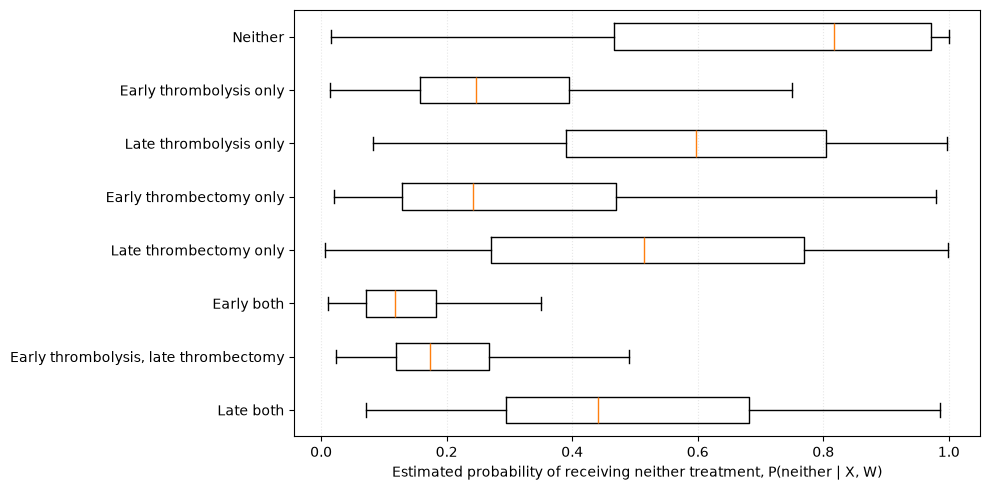

In [10]:
p_neither = propensity[CONTROL_GROUP].to_numpy()
overlap = pd.DataFrame([
    {"treatment_group": g,
     "n": int(mask.sum()),
     "median P(neither)": np.median(p_neither[mask]),
     "% with P(neither) < 0.05": 100 * (p_neither[mask] < 0.05).mean(),
     "% with P(neither) < 0.01": 100 * (p_neither[mask] < 0.01).mean()}
    for g in [CONTROL_GROUP] + GROUP_ORDER
    for mask in [(data["treatment_group"] == g).to_numpy()]
]).round(3)
display(overlap)

fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot([p_neither[(data["treatment_group"] == g).to_numpy()] for g in [CONTROL_GROUP] + GROUP_ORDER],
           vert=False, showfliers=False)
ax.set_yticklabels(["Neither"] + [GROUP_LABELS[g].replace("\n", " ") for g in GROUP_ORDER])
ax.invert_yaxis()
ax.set_xlabel("Estimated probability of receiving neither treatment, P(neither | X, W)")
ax.grid(axis="x", alpha=0.3, linestyle=":")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/{prefix}_overlap.png", dpi=300)
plt.show()

**What this shows:** overlap is adequate for estimating the effect in the treated.

* **Median P(neither):** among treated patients, it ranges from 0.12 (early both) to 0.60 (late thrombolysis only).
* **Patients with very low P(neither):** 11.5% of early-both patients have P(neither) < 0.05. Every other treated group has at most 4.1% below 0.05. Almost no patients are below 0.01: one late-thrombectomy patient (0.05%).

So most treated patients have comparable untreated patients, and the ATT does not depend on extreme weights. Early both has the weakest overlap. The sensitivity analysis that excludes patients with P(neither) < 0.05 tests this.

## Treatment effects

For each strategy compared with neither treatment, three estimates are shown (see the Overview):

* **ATT** (main result): the AIPW estimate of the average effect in patients who received the strategy. Each treated patient's outcome is compared with a doubly robust estimate of their outcome without treatment. This combines the first-stage predictions, the forest, and untreated patients reweighted by the odds P(strategy | X, W) / P(neither | X, W). It is consistent if either the outcome or the treatment model is correct. The 95% CI comes from the influence function.
* **ATE:** the AIPW estimate of the average effect if everyone in the cohort received the strategy. This needs every type of patient to have some chance of receiving the strategy (positivity). Most strategies are given to a selected minority, so for many patients the predicted probability is below 0.01. The ATE is shown as "not estimable" when more than `ATE_MAX_CLIPPED_PCT` (20%) of the cohort is below the clip.
* **Mean CATE in treated:** the simple average of the forest's individual estimates in treated patients. No CI is given, because individual estimates share the same trees and are strongly correlated.

Propensities are clipped at `PROPENSITY_CLIP` (0.01). Effects are differences in the probability of a good outcome, shown in percentage points.

In [11]:
effects = dr_effects(est, X, y, arm)
effects.to_csv(f"{OUTPUT_DIR}/{prefix}_effects.csv", index=False)

# Per-patient CATE for each patient's own strategy (vs neither)
theta = cate_matrix(est, X)
cate_df = data[X_FEATURES + ["treatment_group"]].copy()
cate_df["good_outcome"] = y
cate_df["cate"] = np.nan
for j, group in enumerate(GROUP_ORDER):
    mask = (data["treatment_group"] == group).to_numpy()
    cate_df.loc[mask, "cate"] = theta[mask, j]
cate_df.to_csv(f"{OUTPUT_DIR}/{prefix}_causal_forest_cate_estimates.csv", index=True)


def fmt_pp(point, lower, upper):
    if pd.isna(point):
        return "not estimable (positivity)"
    return f"{100 * point:.1f} ({100 * lower:.1f}, {100 * upper:.1f})"


effects_table = pd.DataFrame({
    "Treatment group": effects["treatment_group"].str.replace("_", " "),
    "n": effects["n"],
    "ATT, % points (95% CI)": [fmt_pp(*r) for r in effects[["att", "att_ci_lower", "att_ci_upper"]].to_numpy()],
    "ATE, % points (95% CI)": [fmt_pp(*r) for r in effects[["ate", "ate_ci_lower", "ate_ci_upper"]].to_numpy()],
    "% of cohort with P(strategy) < 0.01": effects["pct_cohort_p_below_clip"].round(1),
    "Mean CATE in treated, % points": (100 * effects["mean_cate"]).round(1),
    "SD of CATE between patients": (100 * effects["cate_sd_between_patients"]).round(1),
})
effects_table.to_csv(f"{OUTPUT_DIR}/{prefix}_effects_table.csv", index=False)
effects_table

,Treatment group,n,"ATT, % points (95% CI)","ATE, % points (95% CI)",% of cohort with P(strategy) < 0.01,"Mean CATE in treated, % points",SD of CATE between patients
0,early thrombolysis only,27675,"9.9 (8.8, 11.0)","8.8 (7.7, 9.8)",18.4,9.9,6.0
1,late thrombolysis only,1189,"9.5 (6.5, 12.5)",not estimable (positivity),82.0,8.5,17.0
2,early thrombectomy only,1107,"12.1 (7.4, 16.8)",not estimable (positivity),84.4,12.5,15.1
3,late thrombectomy only,1876,"9.4 (7.1, 11.7)",not estimable (positivity),64.8,7.5,11.7
4,early both,2307,"15.2 (10.9, 19.6)",not estimable (positivity),73.1,16.8,12.4
5,early thrombolysis late thrombectomy,2714,"9.3 (6.8, 11.7)",not estimable (positivity),53.9,8.1,10.7
6,late both,141,"15.4 (6.6, 24.2)",not estimable (positivity),99.2,13.5,31.7


### Why not EconML's built-in doubly robust estimates?

For comparison, the next cell shows EconML's `att__inference` alongside the AIPW ATT used here, together with the smallest predicted probability of each patient's *own* treatment among the treated. EconML divides by these probabilities without clipping.

In [12]:
builtin = []
arm_levels = sorted(np.unique(arm))
for k, level in enumerate(arm_levels):
    if level == BASELINE_ARM:
        continue
    group = level.split("_", 1)[1]
    mask = (data["treatment_group"] == group).to_numpy()
    builtin.append({
        "treatment_group": group,
        "EconML att__inference, % points": round(100 * float(np.ravel(est.att__inference(T=k).point_estimate)[k - 1]), 1),
        "AIPW ATT (clipped), % points": round(100 * float(effects.set_index("treatment_group").loc[group, "att"]), 1),
        "smallest P(own treatment) in treated": propensity[group][mask].min(),
    })
pd.DataFrame(builtin)

,treatment_group,"EconML att__inference, % points","AIPW ATT (clipped), % points",smallest P(own treatment) in treated
0,early_thrombolysis_only,7.5,9.9,4.519983e-04
1,late_thrombolysis_only,-0.5,9.5,8.377582e-05
2,early_thrombectomy_only,69.4,12.1,1.291700e-04
3,late_thrombectomy_only,-10.1,9.4,3.256748e-04
4,early_both,32.8,15.2,9.401188e-05
5,early_thrombolysis_late_thrombectomy,13.1,9.3,5.227933e-04
6,late_both,-8081.7,15.4,6.776382e-07


**What this shows:**

* **EconML's built-in values are implausible for most strategies:**
  * +69.4 points (early thrombectomy only)
  * +32.8 (early both)
  * −10.1 (late thrombectomy only)
  * −8,082 (late both)
* **Why:** some treated patients have a predicted probability of their own treatment as low as 0.0000007 (late both), or about 0.0001–0.0005 (other strategies). Dividing by these gives enormous weights.
* **The fix:** the AIPW ATT used here clips probabilities at 0.01 and reweights only untreated patients. It gives stable estimates that agree with the forest's own averages.

**What this shows:**

* **ATT (main result):** every strategy improves the probability of a good outcome in the patients who received it, and all CIs exclude zero:
  * early thrombolysis only: +9.9 points (8.8 to 11.0)
  * late thrombolysis only: +9.5 (6.5 to 12.5)
  * early thrombectomy only: +12.1 (7.4 to 16.8)
  * late thrombectomy only: +9.4 (7.1 to 11.7)
  * early both: +15.2 (10.9 to 19.6)
  * early thrombolysis, late thrombectomy: +9.3 (6.8 to 11.7)
  * late both: +15.4 (6.6 to 24.2; only 141 patients)
* **Mean CATE in treated:** within 2 points of the ATT for every strategy, so the forest and the doubly robust correction agree.
* **ATE:** can only be estimated for early thrombolysis only (+8.8, 7.7 to 9.8).
  * This is slightly lower than its ATT, consistent with thrombolysis being given to patients who benefit more.
  * For the other strategies, 54–99% of the cohort has less than a 1% predicted chance of receiving them, so a whole-cohort effect would be pure extrapolation.
* **SD of CATE between patients (6–32 points):** this mixes real differences between patients with estimation noise, so it should not be read as the true spread of effects.

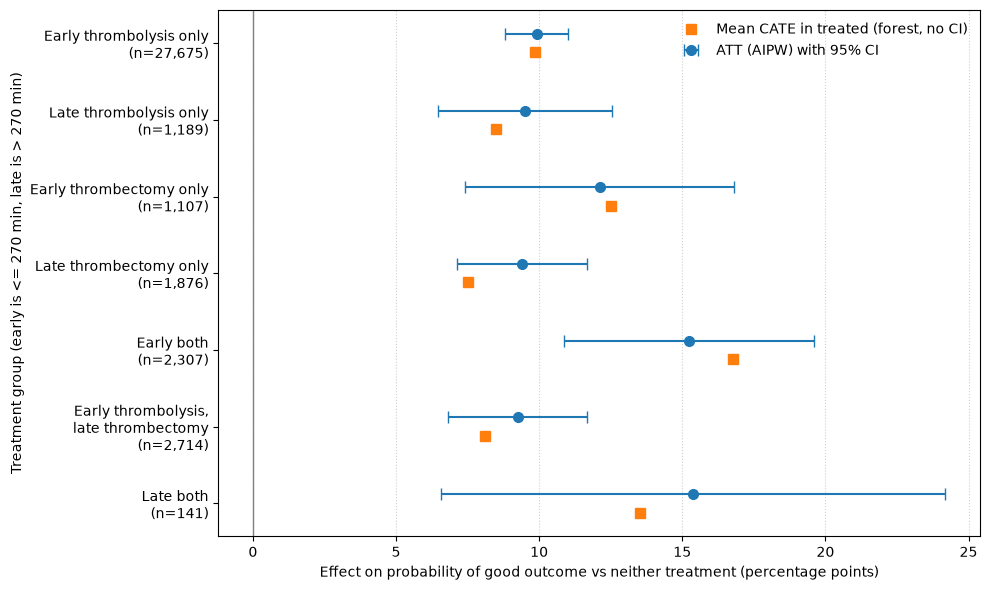

In [13]:
fig, ax = plt.subplots(figsize=(10, 6))
ypos = np.arange(len(effects))[::-1]
point = 100 * effects["att"]
ax.errorbar(point, ypos + 0.12, xerr=[point - 100 * effects["att_ci_lower"], 100 * effects["att_ci_upper"] - point],
            fmt="o", color="#1f77b4", capsize=4, markersize=7, label="ATT (AIPW) with 95% CI")
ax.plot(100 * effects["mean_cate"], ypos - 0.12, "s", color="#ff7f0e", markersize=7,
        label="Mean CATE in treated (forest, no CI)")
ax.set_yticks(ypos)
ax.set_yticklabels([f"{GROUP_LABELS[g]}\n(n={n:,})" for g, n in zip(effects["treatment_group"], effects["n"])])
ax.axvline(0, color="0.5", lw=1)
ax.set_xlabel("Effect on probability of good outcome vs neither treatment (percentage points)")
ax.set_ylabel(f"Treatment group (early is <= {CUTOFF} min, late is > {CUTOFF} min)")
ax.grid(axis="x", linestyle=":", alpha=0.6)
ax.legend(loc="upper right", frameon=False)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/{prefix}_cate.png", dpi=300)
plt.show()

## Heterogeneity of effects

The forest estimates an effect for each patient (CATE). Here those estimates are averaged within subgroups of the treated patients in each strategy, by NIHSS, age and pre-stroke mRS. Subgroups with fewer than 50 patients are not shown.

Individual CATEs are noisy, and these subgroup averages have no CIs, so they show *patterns* rather than precise subgroup effects.

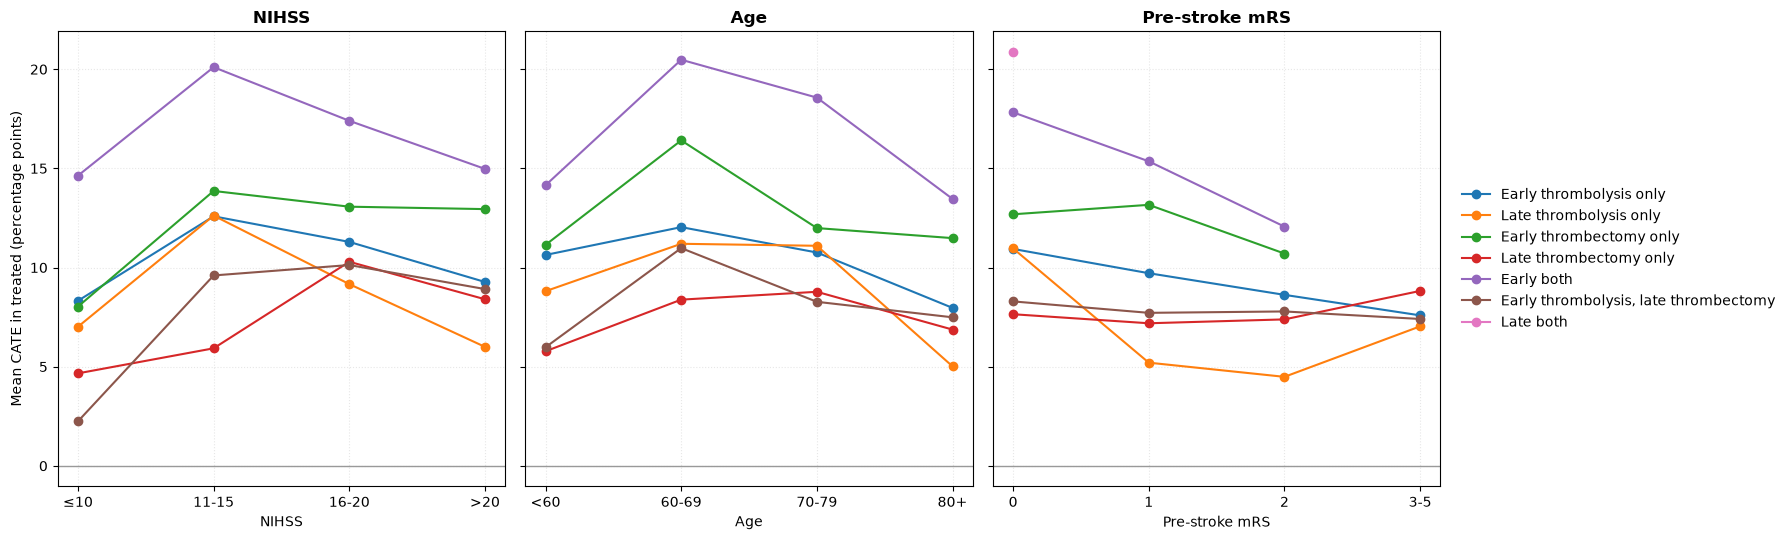

treatment_group       early_thrombolysis_only  late_thrombolysis_only  \
characteristic band                                                     
Age            60-69                     12.0                    11.2   
               70-79                     10.8                    11.1   
               80+                        8.0                     5.0   
               <60                       10.6                     8.8   
NIHSS          11-15                     12.6                    12.6   
               16-20                     11.3                     9.2   
               >20                        9.3                     6.0   
               ≤10                        8.3                     7.0   
Pre-stroke mRS 0                         10.9                    11.0   
               1                          9.7                     5.2   
               2                          8.6                     4.5   
               3-5                        7.6                     7.0   

treatment_group       early_thrombectomy_only  late_thrombectomy_only  \
characteristic band                                                     
Age            60-69                     16.4                     8.4   
               70-79                     12.0                     8.8   
               80+                       11.5                     6.9   
               <60                       11.1                     5.8   
NIHSS          11-15                     13.9                     5.9   
               16-20                     13.1                    10.3   
               >20                       12.9                     8.4   
               ≤10                        8.0                     4.7   
Pre-stroke mRS 0                         12.7                     7.6   
               1                         13.2                     7.2   
               2                         10.7                     7.4   
               3-5                       12.0                     8.8   

treatment_group       early_both  early_thrombolysis_late_thrombectomy  \
characteristic band                                                      
Age            60-69        20.5                                  11.0   
               70-79        18.6                                   8.3   
               80+          13.5                                   7.5   
               <60          14.1                                   6.0   
NIHSS          11-15        20.1                                   9.6   
               16-20        17.4                                  10.1   
               >20          15.0                                   8.9   
               ≤10          14.6                                   2.2   
Pre-stroke mRS 0            17.8                                   8.3   
               1            15.4                                   7.7   
               2            12.1                                   7.8   
               3-5          13.3                                   7.4   

treatment_group       late_both  
characteristic band              
Age            60-69       20.1  
               70-79        8.2  
               80+         18.5  
               <60          9.6  
NIHSS          11-15       17.9  
               16-20       23.6  
               >20         11.5  
               ≤10          2.0  
Pre-stroke mRS 0           20.9  
               1            2.3  
               2           -1.8  
               3-5        -28.4

In [14]:
bands = {
    "NIHSS": pd.cut(data["stroke_severity"], [0, 10, 15, 20, 42], labels=["≤10", "11-15", "16-20", ">20"]),
    "Age": pd.cut(data["age"], [0, 60, 70, 80, 120], right=False, labels=["<60", "60-69", "70-79", "80+"]),
    "Pre-stroke mRS": pd.cut(data["prior_disability"], [-1, 0, 1, 2, 5], labels=["0", "1", "2", "3-5"]),
}
heterogeneity = []
for band_name, band in bands.items():
    grouped = cate_df.assign(band=band).groupby(["treatment_group", "band"], observed=True)["cate"]
    summary = grouped.agg(["mean", "count"]).reset_index()
    summary.insert(0, "characteristic", band_name)
    heterogeneity.append(summary)
heterogeneity = pd.concat(heterogeneity, ignore_index=True)
heterogeneity = heterogeneity[heterogeneity["treatment_group"] != CONTROL_GROUP]
heterogeneity.to_csv(f"{OUTPUT_DIR}/{prefix}_heterogeneity.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)
for ax, band_name in zip(axes, bands):
    for group in GROUP_ORDER:
        h = heterogeneity[(heterogeneity["characteristic"] == band_name)
                          & (heterogeneity["treatment_group"] == group) & (heterogeneity["count"] >= 50)]
        ax.plot(h["band"].astype(str), 100 * h["mean"], marker="o", label=GROUP_LABELS[group].replace("\n", " "))
    ax.set_title(band_name, fontweight="bold")
    ax.set_xlabel(band_name)
    ax.axhline(0, color="0.6", lw=1)
    ax.grid(alpha=0.3, linestyle=":")
axes[0].set_ylabel("Mean CATE in treated (percentage points)")
axes[-1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/{prefix}_heterogeneity.png", dpi=300)
plt.show()

(heterogeneity.assign(mean=lambda d: (100 * d["mean"]).round(1))
 .pivot_table(index=["characteristic", "band"], columns="treatment_group", values="mean", observed=True)
 .reindex(columns=GROUP_ORDER))

**What this shows** (patterns only; subgroup estimates are noisy):

* **Age:** the benefit is smaller in patients aged 80+ for most strategies. For example:
  * early thrombolysis only: +8.0 at 80+ vs +10.6 to +12.0 under 80
  * early both: +13.5 at 80+ vs +18.6 to +20.5 at ages 60–79 (+14.1 under 60)
* **Pre-stroke disability:** the benefit falls as pre-stroke mRS rises:
  * early thrombolysis only: +10.9 at mRS 0 to +7.6 at mRS 3–5
  * early both: +17.8 at mRS 0 to +12.1–13.3
* **Stroke severity:**
  * Thrombolysis and early both: the benefit is largest at NIHSS 11–15 (early thrombolysis only +12.6, early both +20.1) and smaller at NIHSS > 20 and ≤ 10 (early both +15.0 and +14.6).
  * Early thrombectomy only: the benefit is lowest at NIHSS ≤ 10 (+8.0) and similar above that (+12.9 to +13.9).
* **Late both:** estimates jump around between subgroups (for example −28.4 at pre-stroke mRS 3–5), reflecting very small numbers rather than real effects.

## Comparison with the matched target trial emulation

The matched target trial emulation (`4_target_trial_emulation/01_...`) estimates the same quantity, the effect in the treated, by a different method: exact matching on five features. Agreement between the two methods makes the results more credible. Disagreement points to where modelling choices matter.

,Treatment group,Causal forest ATT (95% CI),Matched TTE (95% CI),Difference (CF - TTE)
0,early thrombolysis only,"9.9 (8.8, 11.0)","12.4 (11.6, 13.2)",-2.5
1,late thrombolysis only,"9.5 (6.5, 12.5)","6.3 (2.3, 10.3)",3.2
2,early thrombectomy only,"12.1 (7.4, 16.8)","17.2 (13.3, 21.0)",-5.0
3,late thrombectomy only,"9.4 (7.1, 11.7)","8.3 (5.3, 11.2)",1.1
4,early both,"15.2 (10.9, 19.6)","23.5 (20.8, 26.2)",-8.3
5,early thrombolysis late thrombectomy,"9.3 (6.8, 11.7)","11.0 (8.5, 13.4)",-1.7
6,late both,"15.4 (6.6, 24.2)","17.0 (5.9, 28.1)",-1.6


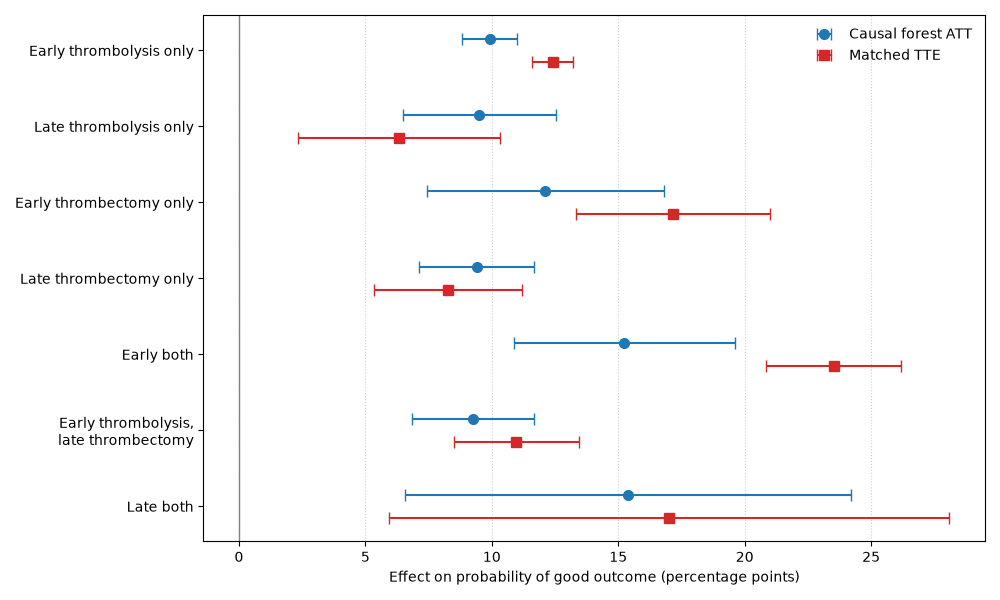

In [15]:
try:
    tte = pd.read_csv(TTE_SUMMARY_PATH)
    tte["treatment_group"] = tte["treatment_group"].str.replace(" ", "_")
    comparison = effects[["treatment_group", "att", "att_ci_lower", "att_ci_upper"]].merge(
        tte[["treatment_group", "difference", "difference_ci_lower", "difference_ci_upper"]], on="treatment_group")
    comparison_table = pd.DataFrame({
        "Treatment group": comparison["treatment_group"].str.replace("_", " "),
        "Causal forest ATT (95% CI)": [fmt_pp(*r) for r in comparison[["att", "att_ci_lower", "att_ci_upper"]].to_numpy()],
        "Matched TTE (95% CI)": [fmt_pp(*r) for r in comparison[["difference", "difference_ci_lower", "difference_ci_upper"]].to_numpy()],
        "Difference (CF - TTE)": (100 * (comparison["att"] - comparison["difference"])).round(1),
    })
    display(comparison_table)

    fig, ax = plt.subplots(figsize=(10, 6))
    ypos = np.arange(len(comparison))[::-1]
    for offset, (prefix_col, label, colour, marker) in zip(
            [0.15, -0.15],
            [(("att", "att_ci_lower", "att_ci_upper"), "Causal forest ATT", "#1f77b4", "o"),
             (("difference", "difference_ci_lower", "difference_ci_upper"), "Matched TTE", "#d62728", "s")]):
        point = 100 * comparison[prefix_col[0]]
        ax.errorbar(point, ypos + offset, xerr=[point - 100 * comparison[prefix_col[1]],
                                                100 * comparison[prefix_col[2]] - point],
                    fmt=marker, color=colour, capsize=4, markersize=7, label=label)
    ax.set_yticks(ypos)
    ax.set_yticklabels([GROUP_LABELS[g] for g in comparison["treatment_group"]])
    ax.axvline(0, color="0.5", lw=1)
    ax.set_xlabel("Effect on probability of good outcome (percentage points)")
    ax.grid(axis="x", linestyle=":", alpha=0.6)
    ax.legend(loc="upper right", frameon=False)
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/{prefix}_vs_target_trial.png", dpi=300)
    plt.show()
except FileNotFoundError:
    print(f"Target trial emulation results not found at {TTE_SUMMARY_PATH}; run that notebook first.")

**What this shows:**

* **The late strategies agree well.** The differences (causal forest − target trial emulation) are:
  * late thrombolysis only: +3.2
  * late thrombectomy only: +1.1
  * early thrombolysis then late thrombectomy: −1.7
  * late both: −1.6
* **The early strategies are smaller with the causal forest:**
  * early both: +15.2 vs +23.5 (CIs do not overlap)
  * early thrombectomy only: +12.1 vs +17.2
  * early thrombolysis only: +9.9 vs +12.4 (CIs do not overlap)

  The ranking also differs. Early both is still among the largest effects with both methods, but the causal forest puts early thrombectomy only closer to the thrombolysis strategies.
* **Why the causal forest is smaller for the early strategies:** it adjusts for more confounders than the five matching features, including comorbidities, stroke team, year and onset-to-scan time. The sensitivity analyses show that onset-to-scan time explains almost all of the gap. Without it, the causal forest gives +24.0, +18.6 and +13.2, within 1.5 points of the target trial emulation.
* **Which estimate is right** depends on whether onset-to-scan time should be adjusted for. See the sensitivity analyses and limitations.

## Sensitivity analyses

Each analysis refits the whole model with **one** change and reports the AIPW ATT.

| Category | Analysis | Why |
|---|---|---|
| Model specification | Original (incorrect) categorical indices | Shows how much the categorical-feature fix changes the results. |
| Confounders | Without stroke team | Tests how much adjustment for hospital practice matters. |
| Confounders | Without onset-to-scan time and year | Onset-to-scan time strongly predicts early vs late treatment, which can reduce overlap. |
| Confounders | Also adjust for LVO (missing as its own category) | LVO strongly influences both thrombectomy and outcome, but is not in the primary model. |
| Overlap | Exclude patients with P(neither) < 0.05 | Removes patients with no comparable untreated patients, so estimates rely less on extreme weights. |
| First stage | Smaller LightGBM models (200 trees, 15 leaves) | Tests sensitivity to first-stage model complexity. |
| Forest | Minimum leaf size 50 | Tests sensitivity to forest settings. |
| Cross-fitting | Folds grouped by stroke team | Each team's patients are predicted by models trained on other teams. |
| Treatment timing | Early/late cut-off 240 or 300 min | Tests the choice of `CUTOFF` = 270 minutes. |
| Outcome | mRS 0–2 only; mRS 0–1 or no worse than pre-stroke; mRS 0–3 or no worse than pre-stroke | Tests the good-outcome definition. |
| Random seed | 3 other seeds | Shows variation from random cross-fitting splits, subsampling and the forest. |

Each refit takes about as long as the primary fit (printed above), so this section is slow. Results are saved to CSV.

In [16]:
# Original categorical indices: X-relative for the outcome model, W-relative for the treatment model.
# Both models actually receive hstack([X, W]), so these pointed at the wrong columns.
X_tmp, W_tmp, *_ = build_matrices(data)
original_cat_idx = [X_tmp.columns.get_loc(c) for c in CATEGORICAL_FEATURES if c in X_tmp.columns]
original_cat_idx_w = [W_tmp.columns.get_loc(c) for c in CATEGORICAL_FEATURES if c in W_tmp.columns]


def fit_original_cat_idx(df):
    # Reproduce the earlier model, where model_y and model_t used different (incorrect) indices
    X_, W_, y_, arm_, _ = build_matrices(df)
    params = dict(NUISANCE_PARAMS, random_state=SEED)
    est_ = CausalForestDML(
        model_y=CatLGBMClassifier(cat_features=original_cat_idx, **params),
        model_t=CatLGBMClassifier(cat_features=original_cat_idx_w, **params),
        discrete_treatment=True, discrete_outcome=True, n_estimators=N_TREES,
        min_samples_leaf=MIN_SAMPLES_LEAF, max_depth=None, honest=True, cv=CV_FOLDS,
        random_state=SEED, n_jobs=-1, verbose=False)
    est_.fit(y_, arm_, X=X_, W=W_, groups=df["patient_id"].to_numpy(), cache_values=True)
    return est_, X_, y_, arm_


no_team = [f for f in W_FEATURES if f != "stroke_team"]
no_scan_year = [f for f in W_FEATURES if f not in ("onset_to_scan_time", "year")]
lvo_cohort = build_cohort(raw_data, extra_features=["lvo"])
trimmed = data[p_neither >= 0.05].copy()
trimmed["patient_id"] = np.arange(len(trimmed))

# (analysis, category, cohort, keyword arguments for fit_causal_forest)
SCENARIOS = [
    ("Without stroke team", "Confounders", data, {"w_features": no_team}),
    ("Without onset-to-scan time and year", "Confounders", data, {"w_features": no_scan_year}),
    ("Also adjust for LVO", "Confounders", lvo_cohort, {"w_features": W_FEATURES + ["lvo"]}),
    ("Exclude P(neither) < 0.05", "Overlap", trimmed, {}),
    ("Smaller LightGBM (200 trees, 15 leaves)", "First stage", data,
     {"nuisance_params": dict(NUISANCE_PARAMS, n_estimators=200, num_leaves=15)}),
    ("Minimum leaf size 50", "Forest", data, {"min_samples_leaf": 50}),
    ("Folds grouped by stroke team", "Cross-fitting", data, {"groups": "team"}),
    ("Early/late cut-off 240 min", "Treatment timing", build_cohort(raw_data, cutoff=240), {}),
    ("Early/late cut-off 300 min", "Treatment timing", build_cohort(raw_data, cutoff=300), {}),
    ("Outcome: mRS 0-2 only", "Outcome definition", data, {"allow_no_worse_than_prior": False}),
    ("Outcome: mRS 0-1 or no worse than pre-stroke", "Outcome definition", data, {"mrs_target": 1}),
    ("Outcome: mRS 0-3 or no worse than pre-stroke", "Outcome definition", data, {"mrs_target": 3}),
    ("Seed 1", "Random seed", data, {"seed": 1}),
    ("Seed 2", "Random seed", data, {"seed": 2}),
    ("Seed 3", "Random seed", data, {"seed": 3}),
]

sensitivity_results = [dr_effects(est, X, y, arm)]
start = time.time()
est_orig, X_orig, y_orig, arm_orig = fit_original_cat_idx(data)
sensitivity_results.append(dr_effects(est_orig, X_orig, y_orig, arm_orig, "Original categorical indices", "Model specification"))
print(f"Original categorical indices: {(time.time() - start) / 60:.1f} min")
# Plug-in mean CATE for comparison with the earlier notebook (0.1105 for early thrombolysis only).
        # That value was reproduced exactly before onset-to-scan time was corrected; it now differs because
        # the corrected onset-to-scan time is used in both models.
mask = (data["treatment_group"] == "early_thrombolysis_only").to_numpy()
print("Original indices, mean CATE, early thrombolysis only (earlier notebook: 0.1105):",
      round(float(est_orig.effect(X_orig.loc[mask].to_numpy(), T0=BASELINE_ARM,
                                  T1=ARM_CODES["early_thrombolysis_only"]).mean()), 4))
for analysis, category, cohort, kwargs in SCENARIOS:
    est_s, X_s, _, y_s, arm_s, seconds = fit_causal_forest(cohort, **kwargs)
    sensitivity_results.append(dr_effects(est_s, X_s, y_s, arm_s, analysis, category))
    print(f"{analysis}: {seconds / 60:.1f} min")
    pd.concat(sensitivity_results).to_csv(f"{OUTPUT_DIR}/{prefix}_sensitivity.csv", index=False)  # save as we go

sensitivity_df = pd.concat(sensitivity_results, ignore_index=True)
sensitivity_df.to_csv(f"{OUTPUT_DIR}/{prefix}_sensitivity.csv", index=False)

Original categorical indices: 6.0 min


Original indices, mean CATE, early thrombolysis only (earlier notebook: 0.1105): 0.0984


Without stroke team: 4.9 min


Without onset-to-scan time and year: 5.3 min


Also adjust for LVO: 3.7 min


Exclude P(neither) < 0.05: 3.6 min


... (7 outputs left out)

Outcome: mRS 0-3 or no worse than pre-stroke: 3.6 min


Seed 1: 3.7 min


Seed 2: 3.6 min


Seed 3: 3.7 min


In [17]:
analysis_order = list(dict.fromkeys(sensitivity_df["analysis"]))
sensitivity_df["att_publish"] = [fmt_pp(*r) for r in sensitivity_df[["att", "att_ci_lower", "att_ci_upper"]].to_numpy()]
sensitivity_table = (sensitivity_df.pivot(index="analysis", columns="treatment_group", values="att_publish")
                     .reindex(index=analysis_order, columns=GROUP_ORDER))
sensitivity_table.columns = [c.replace("_", " ") for c in sensitivity_table.columns]
sensitivity_table.to_csv(f"{OUTPUT_DIR}/{prefix}_sensitivity_table.csv")
sensitivity_table  # ATT, percentage points (95% CI)

,early thrombolysis only,late thrombolysis only,early thrombectomy only,late thrombectomy only,early both,early thrombolysis late thrombectomy,late both
analysis,,,,,,,
Primary,"9.9 (8.8, 11.0)","9.5 (6.5, 12.5)","12.1 (7.4, 16.8)","9.4 (7.1, 11.7)","15.2 (10.9, 19.6)","9.3 (6.8, 11.7)","15.4 (6.6, 24.2)"
Original categorical indices,"9.8 (8.8, 10.8)","9.7 (6.8, 12.6)","11.3 (6.6, 15.9)","8.1 (5.9, 10.3)","16.7 (13.8, 19.6)","9.2 (7.1, 11.3)","18.1 (9.3, 26.9)"
Without stroke team,"9.3 (8.3, 10.4)","9.7 (6.7, 12.6)","12.7 (9.1, 16.3)","6.6 (4.4, 8.8)","16.7 (13.8, 19.5)","8.1 (6.0, 10.3)","20.8 (4.8, 36.8)"
Without onset-to-scan time and year,"13.2 (12.4, 14.1)","8.8 (6.0, 11.5)","18.6 (15.3, 21.8)","9.4 (7.2, 11.7)","24.0 (21.6, 26.5)","12.4 (10.4, 14.4)","17.5 (9.3, 25.8)"
Also adjust for LVO,"9.9 (8.8, 11.1)","10.7 (6.9, 14.6)","19.9 (12.1, 27.6)","11.6 (9.1, 14.2)","18.2 (13.4, 23.0)","11.5 (8.8, 14.3)","18.9 (9.8, 28.1)"
Exclude P(neither) < 0.05,"9.8 (8.7, 10.9)","9.3 (6.2, 12.3)","12.8 (8.7, 16.8)","8.7 (6.4, 11.0)","17.1 (13.7, 20.4)","9.1 (6.7, 11.4)","14.0 (3.9, 24.2)"
"Smaller LightGBM (200 trees, 15 leaves)","10.0 (9.0, 11.1)","9.3 (6.4, 12.3)","13.9 (10.0, 17.8)","9.0 (6.8, 11.2)","17.2 (14.0, 20.4)","9.6 (7.4, 11.8)","14.8 (4.1, 25.4)"
Minimum leaf size 50,"9.9 (8.8, 11.0)","9.5 (6.5, 12.5)","12.0 (7.2, 16.7)","9.4 (7.1, 11.7)","15.2 (10.8, 19.6)","9.2 (6.8, 11.7)","16.3 (7.4, 25.3)"
Folds grouped by stroke team,"7.2 (5.9, 8.5)","7.7 (4.7, 10.7)","12.2 (9.4, 14.9)","6.6 (4.4, 8.8)","16.9 (14.7, 19.0)","7.0 (4.8, 9.2)","-5.1 (-14.6, 4.3)"


**What this shows:**

* **Little effect on the results:**
  * **Categorical-feature fix:** most ATTs change by 1.5 points or less (largest: early both 16.7 with the original indices vs 15.2; late both 18.1 vs 15.4). The invalid confidence intervals were the more important problem in the earlier version.
  * **Model settings:** other random seeds, a larger minimum leaf size, smaller first-stage models and trimming of poor-overlap patients change estimates for the larger groups by about 2 points or less. For example, early thrombolysis only stays at 9.8–10.0 and early both at 15.2–17.2. Early thrombectomy only varies more (9.9 to 13.9), and late both more again (14.0 to 22.3).
  * **Early/late cut-off of 240 or 300 min:** most strategies change by 2 points or less. Late both is the exception (12.6 and 23.5).
* **Larger effect on the results:**
  * **Without onset-to-scan time and year:** the early strategies rise by 3–9 points: early thrombolysis only 13.2, early thrombectomy only 18.6, early both 24.0, early thrombolysis then late thrombectomy 12.4. These are close to the matched target trial emulation. The late strategies change little.
    * Onset-to-scan time strongly predicts early treatment. Whether it should be adjusted for is a judgement.
    * It may capture confounders, such as how a patient presents or reasons for delay.
    * It also largely determines whether early treatment is possible, so adjusting for it compares early-treated patients with untreated patients who were also scanned early. Those untreated patients may often have had a specific reason not to be treated.
    * The same pattern is seen in the mild-stroke analysis.
  * **Also adjusting for LVO:** thrombectomy effects rise (early thrombectomy only 19.9, late thrombectomy only 11.6, early thrombolysis then late thrombectomy 11.5, early both 18.2). This is consistent with untreated LVO patients doing badly.
  * **Folds grouped by stroke team:** most effects fall by up to 3 points (early thrombolysis only 7.2, late thrombectomy only 6.6), early thrombectomy only is unchanged, early both rises slightly (16.9), and late both becomes −5.1 (CI −14.6 to 4.3). When a team's patients are predicted by models trained only on other teams, team-specific practice cannot be adjusted for, so this is a stricter but noisier test.
  * **Without stroke team:** late thrombectomy only falls from 9.4 to 6.6. Other changes are 1.5 points or less, apart from late both.
  * **Outcome definition:**
    * The stricter mRS 0–1 (or no worse) outcome roughly halves the thrombectomy-based effects (early both 7.9, early thrombolysis then late thrombectomy 3.6).
    * mRS 0–3 (or no worse) increases them (early both 20.9).
    * The direction is unchanged.
* **Overall:** every strategy except late both has a CI excluding zero in every analysis. Late both (141 patients) includes zero with team-grouped folds and the mRS 0–1 outcome.

### Forest plot of sensitivity analyses

One panel per treatment strategy. Points are the AIPW ATT (percentage points) with 95% CI. The dashed line is the primary estimate; the grey line is no effect.

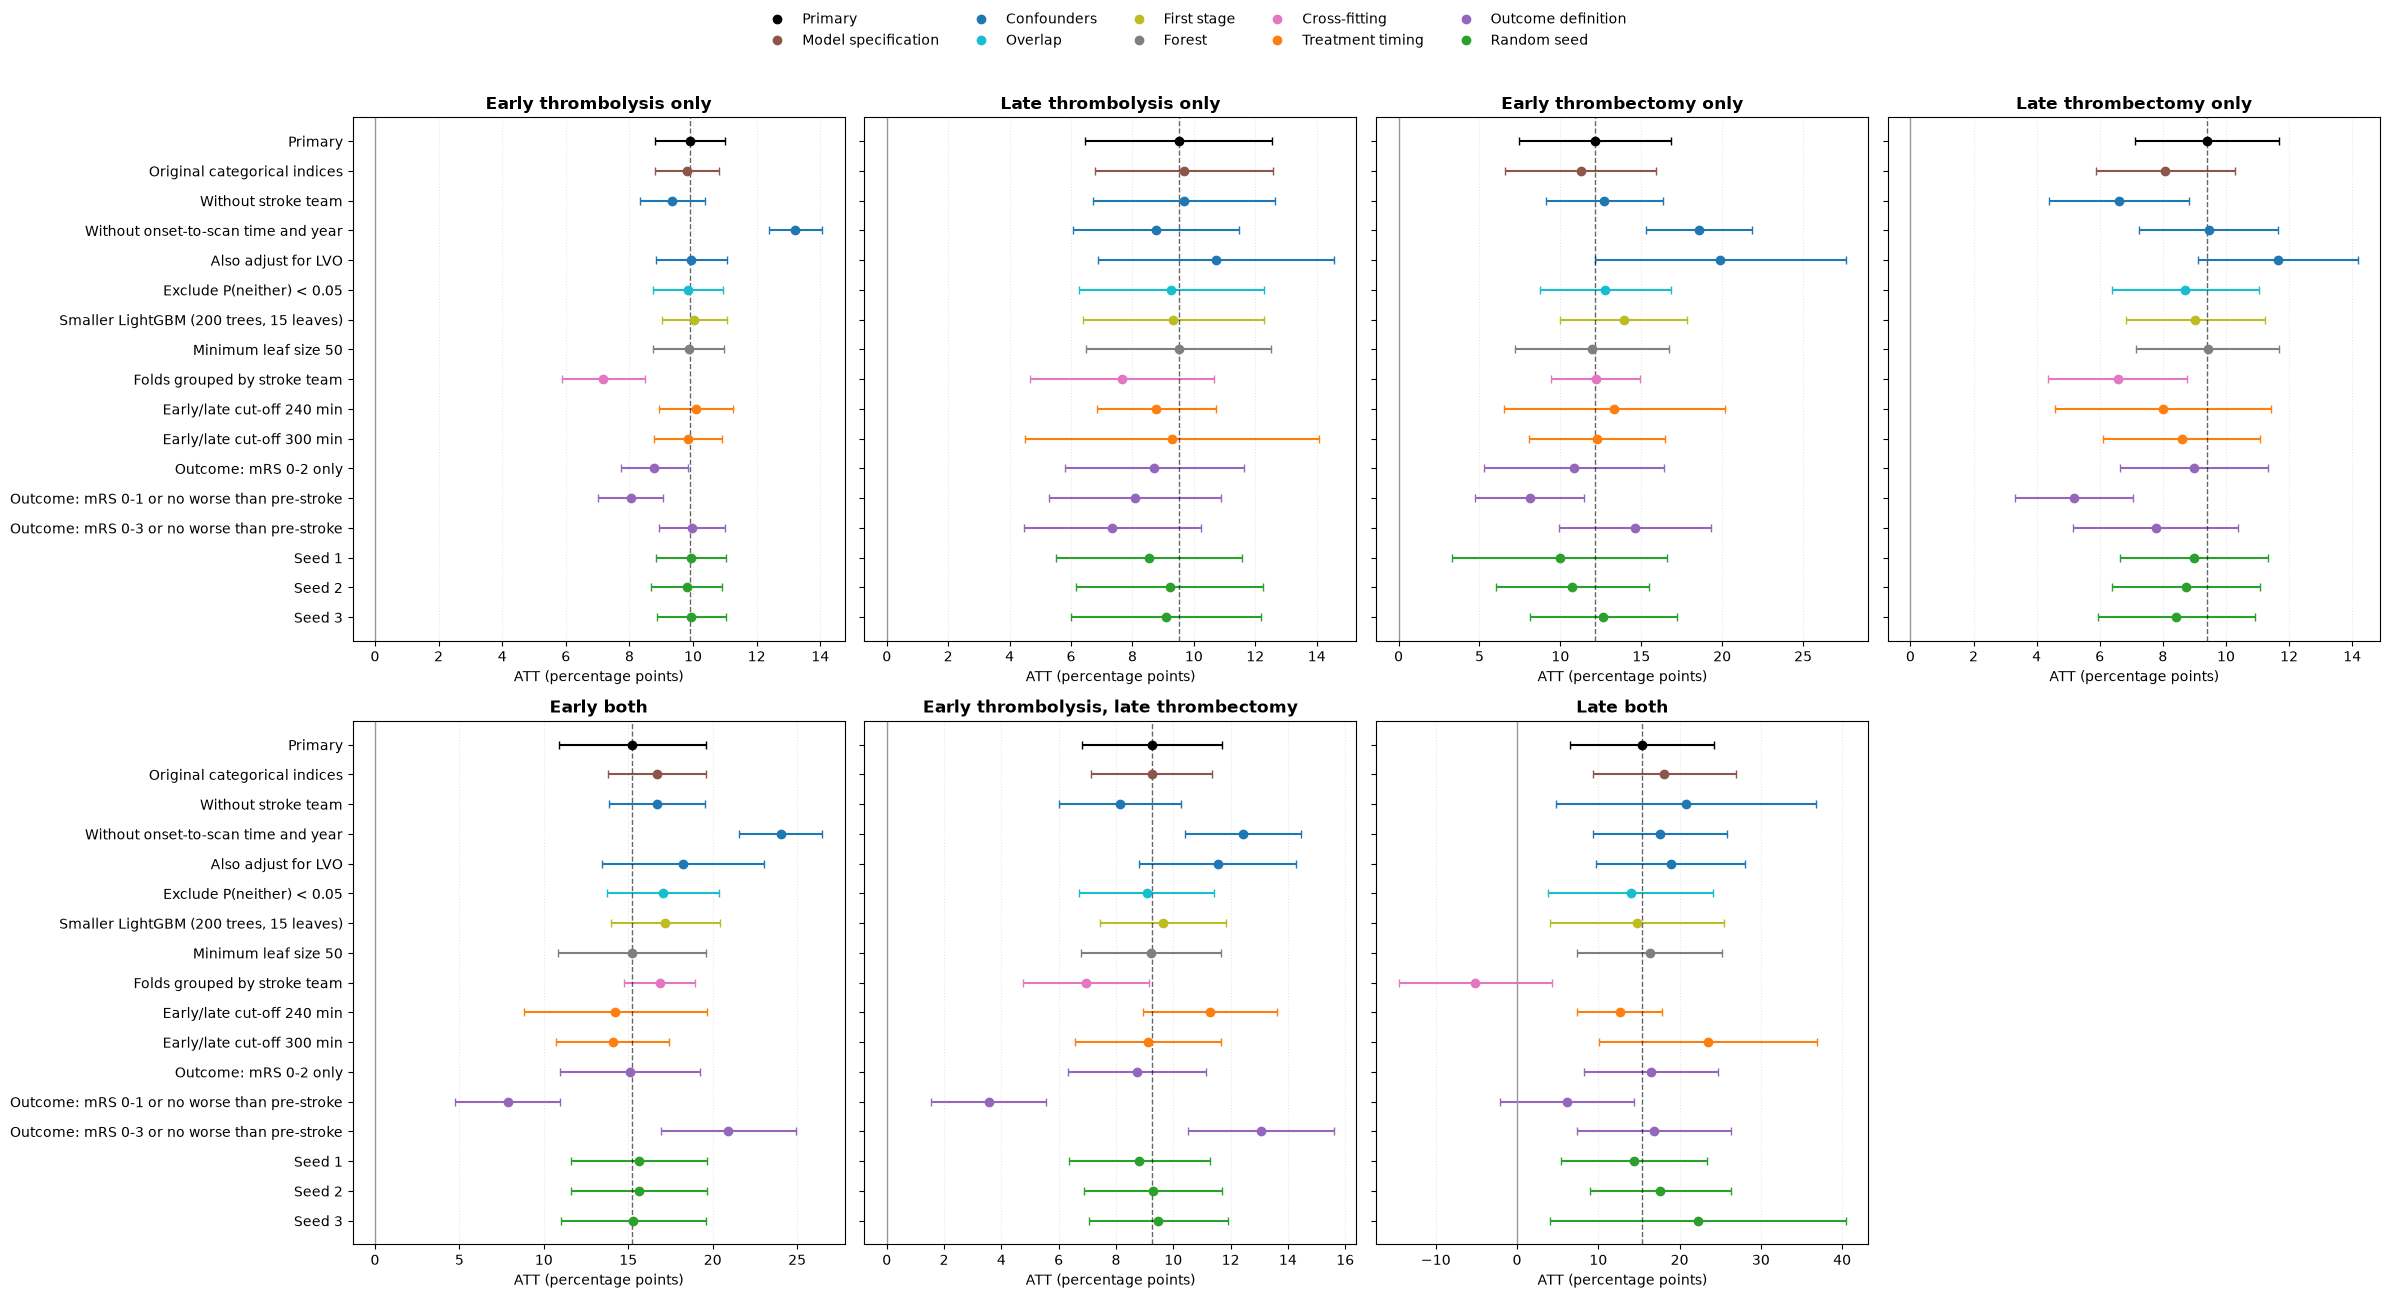

In [18]:
category_colours = {
    "Primary": "black", "Model specification": "#8c564b", "Confounders": "#1f77b4", "Overlap": "#17becf",
    "First stage": "#bcbd22", "Forest": "#7f7f7f", "Cross-fitting": "#e377c2",
    "Treatment timing": "#ff7f0e", "Outcome definition": "#9467bd", "Random seed": "#2ca02c",
}
fig, axes = plt.subplots(2, 4, figsize=(24, 13), sharey=True)
y_pos = {a: i for i, a in enumerate(analysis_order[::-1])}
for ax, group in zip(axes.flat, GROUP_ORDER):
    df = sensitivity_df[sensitivity_df["treatment_group"] == group]
    for _, r in df.iterrows():
        colour = category_colours[r["category"]]
        ax.errorbar(100 * r["att"], y_pos[r["analysis"]],
                    xerr=[[100 * (r["att"] - r["att_ci_lower"])], [100 * (r["att_ci_upper"] - r["att"])]],
                    fmt="o", color=colour, ecolor=colour, capsize=3, markersize=6)
    ax.axvline(100 * df.loc[df["analysis"] == "Primary", "att"].iloc[0], color="black", linestyle="--", lw=1, alpha=0.6)
    ax.axvline(0, color="0.6", lw=1)
    ax.set_title(GROUP_LABELS[group].replace("\n", " "), fontweight="bold")
    ax.set_xlabel("ATT (percentage points)")
    ax.grid(axis="x", alpha=0.3, linestyle=":")
axes.flat[-1].axis("off")
axes[0, 0].set_yticks(list(y_pos.values()))
axes[0, 0].set_yticklabels(list(y_pos.keys()))
for ax in axes[:, 0]:
    ax.tick_params(labelleft=True)
handles = [plt.Line2D([], [], marker="o", color=c, linestyle="", label=k) for k, c in category_colours.items()]
fig.legend(handles=handles, loc="upper center", ncol=5, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(f"{OUTPUT_DIR}/{prefix}_sensitivity.png", dpi=300)
plt.show()

### E-values for unmeasured confounding

The E-value is the minimum strength of association, on the risk-ratio scale, that an unmeasured confounder would need with **both** treatment and outcome (beyond those adjusted for) to fully explain away the effect (VanderWeele & Ding, *Ann Intern Med* 2017;167:268–274).

The ATT is a risk difference. To turn it into a risk ratio, the treated patients' observed good-outcome proportion (p₁) is compared with their estimated proportion had they not been treated, p₀ = p₁ − ATT. The same is done for the CI limit closest to no effect. This conversion is approximate.

In [19]:
def e_value(rr):
    rr = np.asarray(rr, dtype=float)
    rr = np.where(rr < 1, 1 / rr, rr)
    return rr + np.sqrt(rr * (rr - 1))

ev = effects[["treatment_group", "n", "att", "att_ci_lower", "att_ci_upper"]].copy()
ev["p_treated"] = [y[data["treatment_group"].to_numpy() == g].mean() for g in ev["treatment_group"]]
ev["risk_ratio"] = ev["p_treated"] / (ev["p_treated"] - ev["att"])
closest = np.where(ev["att"] >= 0, ev["att_ci_lower"], ev["att_ci_upper"])
crosses_null = (ev["att_ci_lower"] <= 0) & (ev["att_ci_upper"] >= 0)
ev["e_value"] = e_value(ev["risk_ratio"])
ev["e_value_ci"] = np.where(crosses_null, 1.0, e_value(ev["p_treated"] / (ev["p_treated"] - closest)))
ev.to_csv(f"{OUTPUT_DIR}/{prefix}_e_values.csv", index=False)
ev.round(3)

,treatment_group,n,att,att_ci_lower,att_ci_upper,p_treated,risk_ratio,e_value,e_value_ci
0,early_thrombolysis_only,27675,0.099,0.088,0.110,0.490,1.254,1.818,1.737
1,late_thrombolysis_only,1189,0.095,0.065,0.125,0.472,1.252,1.814,1.588
2,early_thrombectomy_only,1107,0.121,0.074,0.168,0.388,1.453,2.265,1.777
3,late_thrombectomy_only,1876,0.094,0.071,0.117,0.336,1.388,2.123,1.853
4,early_both,2307,0.152,0.109,0.196,0.463,1.490,2.345,1.939
5,early_thrombolysis_late_thrombectomy,2714,0.093,0.068,0.117,0.372,1.331,1.995,1.749
6,late_both,141,0.154,0.066,0.242,0.440,1.538,2.447,1.630


**What this shows:**

* **E-values for the point estimates** range from 1.81 (late thrombolysis only) to 2.45 (late both). Early both is 2.35 and early thrombolysis only is 1.82.
* **E-values for the CI limits** range from 1.59 to 1.94.
* **What that means:** to explain away the early-both effect, an unmeasured confounder would need a risk ratio of at least about 1.9 with both treatment and good outcome, beyond everything already adjusted for. That is a moderately strong confounder.
* **Comparison with mild stroke:** these E-values are larger than in the mild-stroke analysis, because good outcome is less common here, so the same absolute difference is a larger risk ratio.

## Conclusions and limitations

### Conclusions

* **All strategies help:** after adjustment with a doubly robust causal forest, every thrombolysis and thrombectomy strategy is associated with a higher probability of a good outcome at discharge in the patients who received it. The gain ranges from about 9 to 15 percentage points.
* **Timing:** early thrombolysis plus early thrombectomy has the largest well-estimated benefit (+15.2), and earlier thrombectomy is better than later. The benefit of early vs late thrombolysis alone is small.
* **Agreement with matching:**
  * The causal forest and the matched target trial emulation agree closely for the late strategies.
  * The causal forest gives smaller effects for the early strategies, by 2.5 to 8 points.
  * The difference is explained by adjustment for onset-to-scan time. Without it, the two methods agree closely.
* **Robustness:** the findings are robust to model settings and random seeds. They are more sensitive to which confounders are included (onset-to-scan time, LVO) and to how stroke-team differences are handled.

### Limitations

* **Unmeasured confounding:** the estimates assume all important confounders are measured. Not captured:
  * LVO status, for most untreated patients
  * imaging findings
  * contraindications
  * reasons treatment was not given

  The E-values (1.6–1.9 at the CI limit) show how strong such confounding would need to be.
* **Choice of adjustment variables:** including onset-to-scan time changes the early-strategy effects by 3–9 points. It is unclear whether it should be treated as a confounder. The primary estimates (with it) and the sensitivity estimates (without it) can be seen as plausible lower and upper values.
* **Positivity.** Most strategies are given to a selected minority, so whole-cohort effects (ATE) cannot be estimated for them. Propensities had to be clipped (at 0.01) for stable doubly robust estimates.
* **Timing of treatment and time zero.** As in the target trial emulation, strategies are defined by when treatment was actually given. A patient who died or deteriorated before late treatment is counted as untreated, which can favour the late strategies.
* **Statistical details.**
  * The AIPW confidence intervals treat the first-stage predictions as fixed and use in-sample forest estimates.
  * Subgroup patterns have no CIs.
  * Results for late both (141 patients) are unstable.
* **Outcome at discharge.** This is not the 90-day mRS, and it depends on length of stay and discharge arrangements.